<a href="https://colab.research.google.com/github/ManarAlmusalam-uni/image-processing-Lab6/blob/main/Lab6_Frequency_Domain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 6 — Frequency Domain Filtering

## Setup — Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from numpy.fft import fft2, ifft2, fftshift, ifftshift

%matplotlib inline

---
## Theory — What is Frequency Domain?

Up to now (Labs 5) we filtered by **convolution in the spatial domain** — sliding a kernel over pixels. The **frequency domain** is a different way of thinking about the same image.

### Every image is a sum of waves
The **Fourier Transform** says any image can be written as a sum of sine waves of different frequencies, orientations, and amplitudes.
- **Low frequencies** → slow variations → smooth regions, overall brightness.
- **High frequencies** → fast variations → edges, fine texture, noise.
<img src="https://drive.google.com/uc?export=view&id=15Ys4pawYnCFgLVSqpFi5T1FUll8MHYSv" width="250">
<img src="https://drive.google.com/uc?export=view&id=1NP0vKa22ZuahSmvsPKlN1e1WGavvu71D" width="600">


<img src="https://drive.google.com/uc?export=view&id=15RwTeJMO-IUdSH2e8RXfDi7tkui-UQ_n" width="700">

### Why bother?
Because filtering in the frequency domain is **very intuitive**:
- Want to blur the image? → **kill the high frequencies**.
- Want to sharpen it? → **boost the high frequencies**.
- Want to find edges? → **keep only the high frequencies**.


Mathematically, convolution in space = **multiplication** in frequency:


So instead of convolving a kernel with the image, we:
1. Take the FFT of the image → `F`
2. Multiply by a filter `H`
3. Take the inverse FFT to get the filtered image back

### Key functions in `numpy.fft`

| Function | Purpose |
|---|---|
| `fft2(image)` | 2D Fast Fourier Transform |
| `ifft2(F)` | Inverse 2D FFT (back to image) |
| `fftshift(F)` | Moves zero-frequency to the center (for viewing) |
| `ifftshift(H)` | Moves zero-frequency back to the top-left corner |
| `fftfreq(N)` | Generates frequency values for an N-point FFT |


## Task 1 — Laplacian in the Frequency Domain

In the **spatial domain**, the Laplacian is a 3×3 kernel:

$$\begin{bmatrix} 0 & 1 & 0 \\ 1 & -4 & 1 \\ 0 & 1 & 0 \end{bmatrix}$$

In the **frequency domain**, the exact same Laplacian operator has this expression:

$$H(u,v) = -4\pi^2(u^2 + v^2)$$


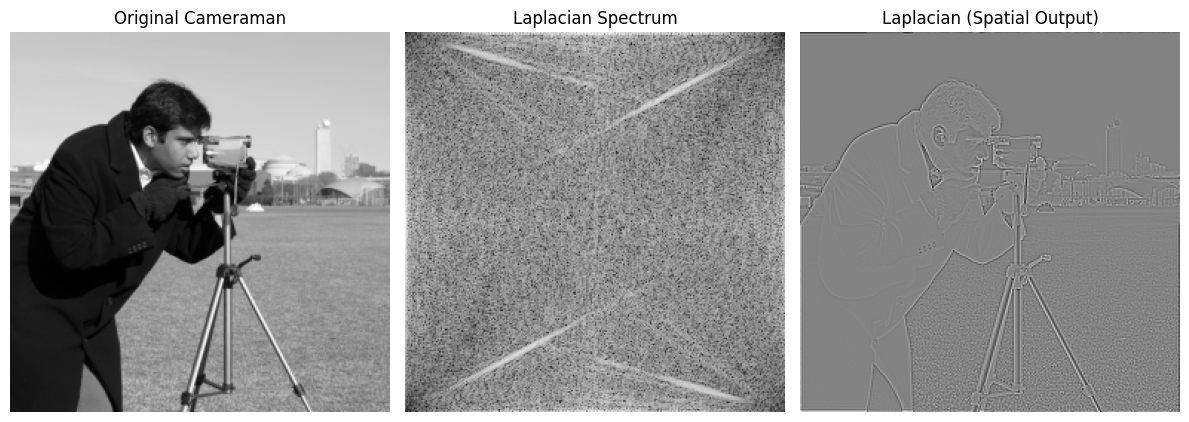

In [2]:
# --- Code from the lab manual ---
# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))   # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)   # column vector of frequencies for rows
v = np.fft.fftfreq(N).reshape(1, -1)   # row vector of frequencies for columns

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain (pointwise multiplication)
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman'); plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum'); plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)'); plt.axis('off')

plt.tight_layout(); plt.show()

### Understanding the output
- The **Laplacian spectrum** (middle image) shows the FFT magnitude after filtering. You can see the corners are bright — that's where the high frequencies live in the un-shifted FFT. The center is dark — low frequencies were killed because the filter is zero there.
- The **spatial output** (right image) shows what the filter returned in the image domain. It looks like an **edge map** — flat regions are gray (≈ 0) and edges stand out.

---
## Assessment Task — Sobel Filter in the Frequency Domain

Sobel filters detect edges — one kernel for horizontal edges (`sobel_x`), one for vertical edges (`sobel_y`). In the spatial domain these are 3×3 kernels:

$$\text{Sobel}_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix} \quad \text{Sobel}_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix}$$

### Why this task is trickier than Task 1
For the Laplacian, we had a clean closed-form formula `−4π²(u² + v²)` that worked directly on the frequency grid. For Sobel, we only have 3×3 kernels. To use them in the frequency domain, we must:

1. **Pad** each 3×3 kernel to the image's size (e.g., 256×256) by placing it in the **center** of a zero-filled array.
2. Apply `ifftshift` to move the kernel's center from the image center to pixel (0, 0) — the convention FFT expects.
3. FFT the padded kernel to get its frequency response.
4. Multiply with the image's FFT.
5. Inverse FFT to get the result.

The helper function `center_embed_kernel` (provided in the lab) does steps 1–3 for us.

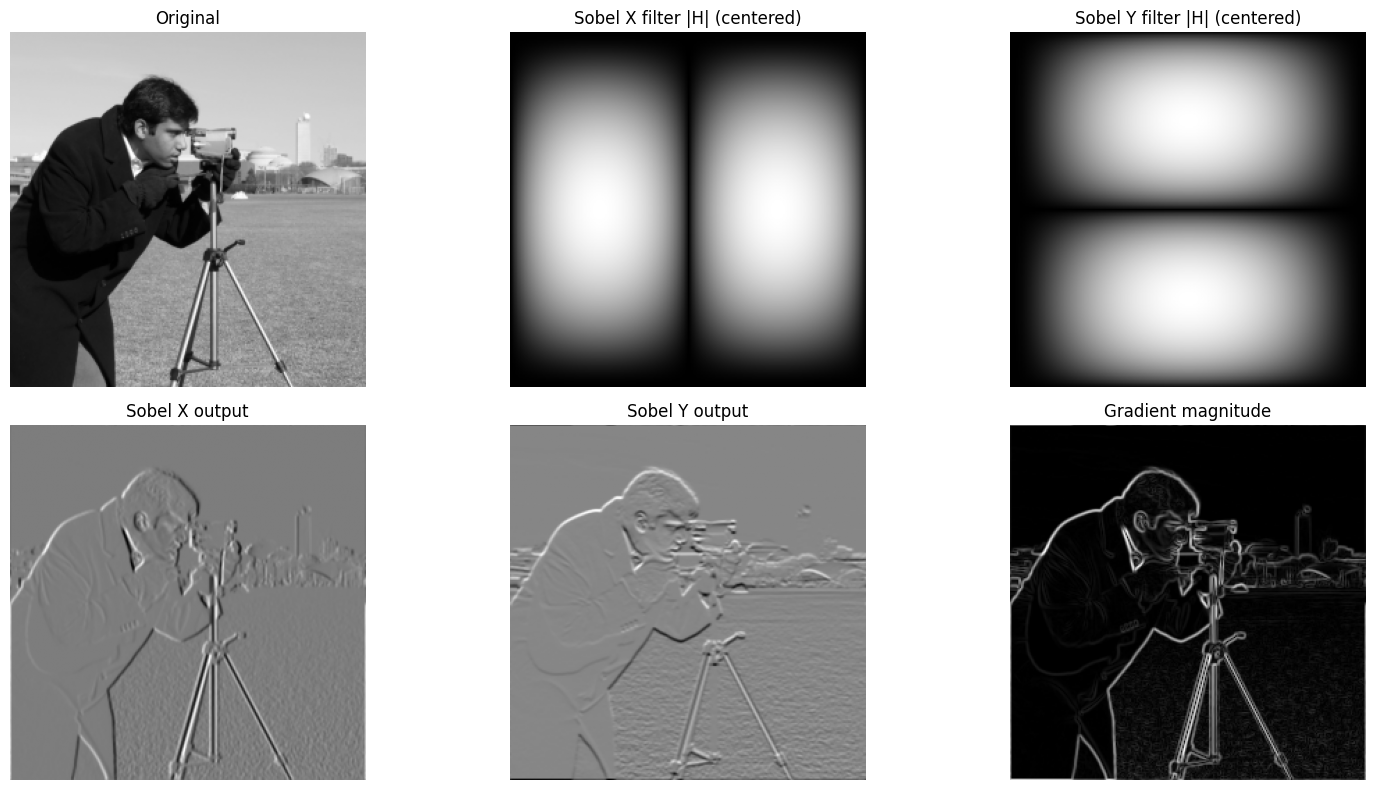

Max difference vs spatial convolution (X): 1.4883927423881005e-15
Max difference vs spatial convolution (Y): 2.8380076066980564e-15


In [10]:
def center_embed_kernel(kernel, shape):
    """Pad a small kernel to `shape`, centered, then ifftshift so its center
    sits at (0,0), and return its 2D FFT (the filter's frequency response)."""
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    top  = shape[0] // 2 - kh // 2   # so kernel center lands exactly on index shape//2
    left = shape[1] // 2 - kw // 2
    padded[top:top + kh, left:left + kw] = kernel   # 1. pad (centered)
    padded = ifftshift(padded)                      # 2. move center to (0,0)
    return fft2(padded)                             # 3. FFT of the kernel

# Spatial-domain Sobel kernels
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=float)
sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]], dtype=float)

# Frequency responses
H_sx = center_embed_kernel(sobel_x, image.shape)
H_sy = center_embed_kernel(sobel_y, image.shape)

# 4. Multiply with the image's FFT
F = fft2(image)
Gx = F * H_sx
Gy = F * H_sy

# 5. Inverse FFT
sobel_x_img = np.real(ifft2(Gx))
sobel_y_img = np.real(ifft2(Gy))
sobel_mag   = np.sqrt(sobel_x_img**2 + sobel_y_img**2)

# Plot
plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1); plt.imshow(image, cmap='gray')
plt.title('Original'); plt.axis('off')

plt.subplot(2, 3, 2); plt.imshow(fftshift(np.log(1 + np.abs(H_sx))), cmap='gray')
plt.title('Sobel X filter |H| (centered)'); plt.axis('off')

plt.subplot(2, 3, 3); plt.imshow(fftshift(np.log(1 + np.abs(H_sy))), cmap='gray')
plt.title('Sobel Y filter |H| (centered)'); plt.axis('off')

plt.subplot(2, 3, 4); plt.imshow(sobel_x_img, cmap='gray')
plt.title('Sobel X output'); plt.axis('off')

plt.subplot(2, 3, 5); plt.imshow(sobel_y_img, cmap='gray')
plt.title('Sobel Y output'); plt.axis('off')

plt.subplot(2, 3, 6); plt.imshow(sobel_mag, cmap='gray')
plt.title('Gradient magnitude'); plt.axis('off')

plt.tight_layout(); plt.show()

# Sanity check: compare with spatial-domain convolution (circular boundary,
# since the FFT implicitly wraps the image around)
from scipy.ndimage import convolve
ref_x = convolve(image, sobel_x, mode='wrap')
ref_y = convolve(image, sobel_y, mode='wrap')
print('Max difference vs spatial convolution (X):', np.abs(sobel_x_img - ref_x).max())
print('Max difference vs spatial convolution (Y):', np.abs(sobel_y_img - ref_y).max())

---
## Summary Table

| Filter | What it does | How it's built in frequency domain |
|---|---|---|
| **Laplacian** (high-pass) | Edge detection, sharpening | `H = −4π²(u² + v²)` |
| **Sobel** (high-pass) | Directional edge detection | Pad 3×3 kernel, `ifftshift`, FFT |
| **Ideal Low-Pass** | Hard blur (causes ringing) | `H = 1 if D ≤ D0 else 0` |
| **Gaussian Low-Pass** | Smooth blur (no ringing) | `H = exp(−D² / 2D0²)` |
| **Gaussian High-Pass** | Edge enhancement | `H = 1 − Gaussian LP` |

## The general recipe for any frequency-domain filter

```python
# 1. Load image
image = data.camera()

# 2. Compute FFT
F = fft2(image)

# 3. Design filter H in frequency space (same shape as image)
H = ...  # Laplacian, Gaussian LP, Sobel, etc.

# 4. Multiply (not convolve!)
G = F * H

# 5. Inverse FFT to get filtered image
filtered = np.real(ifft2(G))
```

**Remember:**
- Keep FFTs in their natural un-shifted order for **computation**.
- Only `fftshift` for **display**, then `ifftshift` before filtering if needed.
- Ignore the imaginary part with `.real` or `np.real()` after `ifft2` — it should be numerically near zero for real-valued filters.

**End of notebook.**